In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine

load_dotenv(find_dotenv(usecwd=True), override=True)
engine = create_engine(os.getenv("DATABASE_URL"))

pd.read_sql("SELECT COUNT(*) AS pedidos FROM pedidos", engine)

,pedidos
0,2006


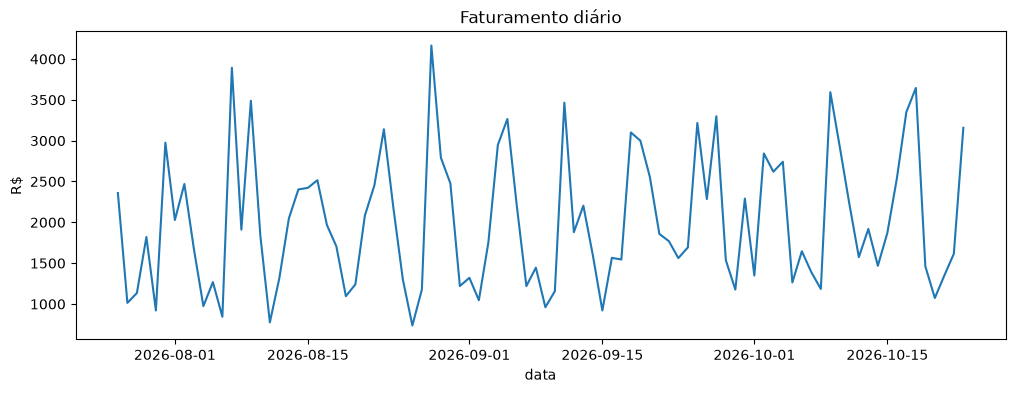

In [2]:
df = pd.read_sql("SELECT * FROM vw_faturamento_diario ORDER BY data", engine)

df.plot(x="data", y="faturamento", figsize=(12, 4), legend=False,
        title="Faturamento diário")
plt.ylabel("R$")
plt.show()

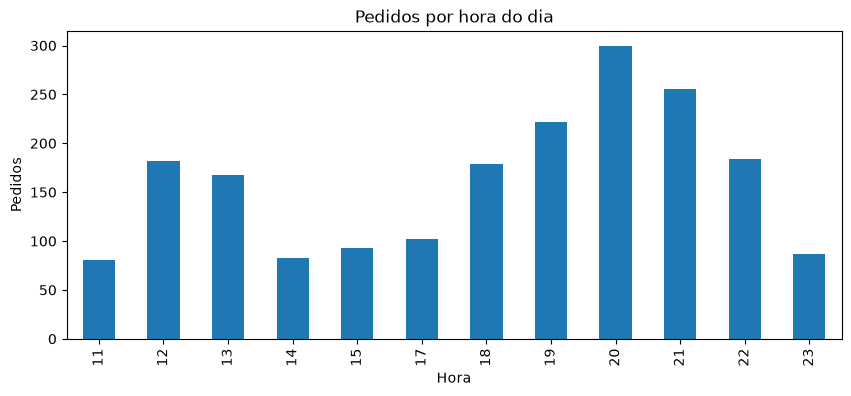

In [3]:
df = pd.read_sql("""
    SELECT hora, COUNT(*) AS pedidos
    FROM vw_pedidos_detalhe
    WHERE status <> 'cancelado'
    GROUP BY hora
    ORDER BY hora
""", engine)

df.plot.bar(x="hora", y="pedidos", figsize=(10, 4), legend=False,
            title="Pedidos por hora do dia")
plt.xlabel("Hora")
plt.ylabel("Pedidos")
plt.show()

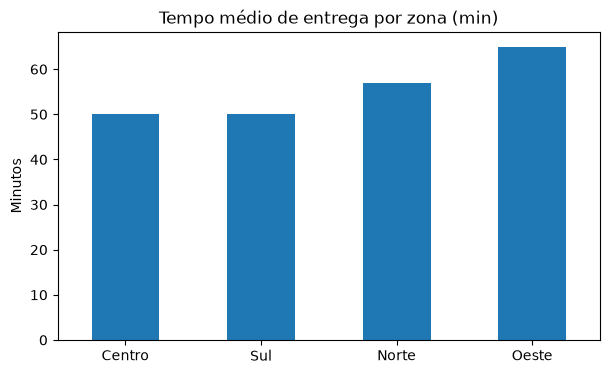

In [4]:
df = pd.read_sql("SELECT * FROM vw_entregas_zona ORDER BY minutos_medio", engine)

df.plot.bar(x="zona", y="minutos_medio", figsize=(7, 4), legend=False,
            title="Tempo médio de entrega por zona (min)")
plt.xlabel("")
plt.ylabel("Minutos")
plt.xticks(rotation=0)
plt.show()

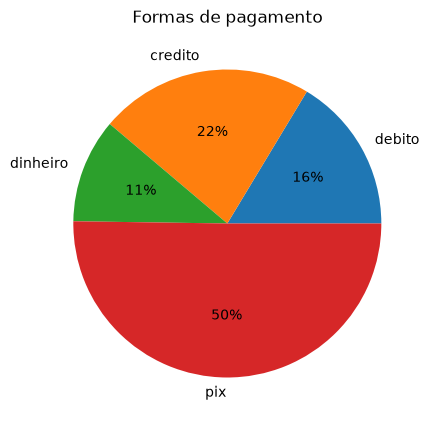

In [5]:
df = pd.read_sql("""
    SELECT forma_pagamento, COUNT(*) AS pagamentos
    FROM vw_pedidos_detalhe
    WHERE forma_pagamento IS NOT NULL
    GROUP BY forma_pagamento
""", engine)

df.set_index("forma_pagamento")["pagamentos"].plot.pie(
    autopct="%1.0f%%", figsize=(5, 5), ylabel="", title="Formas de pagamento")
plt.show()

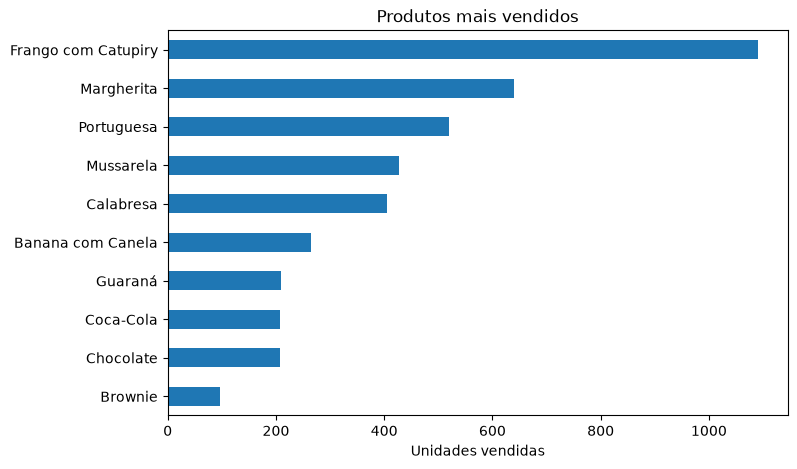

In [6]:
df = pd.read_sql("""
    SELECT produto, SUM(quantidade) AS quantidade
    FROM vw_vendas_produto
    GROUP BY produto
    ORDER BY quantidade DESC
""", engine)

ax = df.plot.barh(x="produto", y="quantidade", figsize=(8, 5), legend=False,
                  title="Produtos mais vendidos")
ax.invert_yaxis()
plt.xlabel("Unidades vendidas")
plt.ylabel("")
plt.show()

In [7]:
pd.read_sql("""
    SELECT nome, unidade_medida, estoque_atual, estoque_minimo, situacao
    FROM vw_situacao_estoque
    ORDER BY cobertura_sobre_minimo
""", engine).head(10)

,nome,unidade_medida,estoque_atual,estoque_minimo,situacao
0,Guaraná lata 350ml,un,133.880,30.0,Ok
1,Coca-Cola lata 350ml,un,135.680,30.0,Ok
2,Manjericão,g,689.170,150.0,Ok
3,Granulado,g,2346.440,500.0,Ok
4,Azeitona,g,3901.720,800.0,Ok
5,Coca-Cola 2L,un,61.160,12.0,Ok
6,Guaraná 2L,un,62.940,12.0,Ok
7,Brownie pronto,un,54.060,10.0,Ok
8,Canela,g,546.052,100.0,Ok
9,Orégano,g,554.184,100.0,Ok
